# HW2 — Uniform Convergence and the Limits of Learning

**Statistical and Machine Learning — M2 IMDS, Université de Haute-Alsace**
**Author:** Jana Dannawi

## Objective
This notebook studies uniform convergence and the limits of learning through Monte-Carlo
simulation of the probability distributions that appear in the theory:

- **Part I**: how empirical risks $L_S(h)$ fluctuate around true risks $L_\mathcal{D}(h)$,
  for one hypothesis and for a whole finite class, as a function of $m$ and $|H|$;
- **Part II**: the No-Free-Lunch phenomenon, with completely random target functions;
- **Part III**: how prior knowledge (threshold targets and a threshold hypothesis class)
  allows generalization.

Only `numpy` and `matplotlib` are used. A fixed random seed makes all results reproducible.

## Experimental choices

| parameter | values | justification |
|---|---|---|
| true risks $p_j$ | 0.05, 0.1, 0.2, 0.3, 0.5 | from low variance ($p$ small) to the worst case $p=0.5$, where $p(1-p)$ is maximal |
| sample sizes $m$ | 10 to 3000 (log scale) | covers small samples (large fluctuations) up to large samples (strong concentration) |
| accuracy $\epsilon$ | 0.1 | the Hoeffding bound becomes non-trivial for $m > \ln 2/(2\epsilon^2) \approx 35$, inside our range of $m$ |
| confidence $\delta$ | 0.05 | standard value |
| class sizes $\lvert H \rvert$ | 5, 10, 50, 100, 500 | two orders of magnitude, to observe the $\log\lvert H\rvert$ dependence |
| domain sizes $N$ | 20, 100, 1000 | to check that results depend on $m/N$ |
| repetitions $R$ | 2,000 to 200,000 | large enough for the Monte-Carlo error $\approx \sqrt{P(1-P)/R}$ to be small compared with the probabilities measured |

---
## Part I — Simulating Uniform Convergence

We consider a finite class $H = \{h_1, \dots, h_K\}$ where each hypothesis has a fixed true risk
$L_\mathcal{D}(h_j) = p_j$. On a training sample of size $m$, the number of errors of $h_j$ is

$$E_j \sim \mathrm{Binomial}(m, p_j), \qquad L_S(h_j) = \frac{E_j}{m}.$$

From the properties of the binomial distribution:

$$\mathbb{E}[L_S(h_j)] = p_j, \qquad \mathrm{sd}(L_S(h_j)) = \sqrt{\frac{p_j(1-p_j)}{m}}.$$

### Question 1 — Empirical risk as a random variable
We fix one hypothesis ($p = 0.3$), simulate $L_S(h)$ $R = 50{,}000$ times for several values
of $m$, plot its distribution and compare its mean with the true risk.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

# True risks p_1, ..., p_K of the hypotheses (chosen by us)
p_values = np.array([0.05, 0.10, 0.20, 0.30, 0.50])


j = 3
p = p_values[j]

m_list = [10, 30, 100, 300, 1000, 3000]
R = 50_000

print("True risks:", p_values)
print(f"Studied hypothesis: h_{j+1}, L_D(h) = p = {p}")

True risks: [0.05 0.1  0.2  0.3  0.5 ]
Studied hypothesis: h_4, L_D(h) = p = 0.3


(a) For each m: R independent draws of the number of errors

In [2]:
E = {m: rng.binomial(m, p, size=R) for m in m_list}

for m in m_list:
    print(f"m = {m:>4} : first 8 values of E = {E[m][:8]}")

m =   10 : first 8 values of E = [2 3 3 2 2 4 5 2]
m =   30 : first 8 values of E = [11 10 11  8 10 12 10 12]
m =  100 : first 8 values of E = [27 26 19 29 32 35 39 24]
m =  300 : first 8 values of E = [ 85  79  91  74  87  80 105  90]
m = 1000 : first 8 values of E = [292 324 297 289 304 284 285 326]
m = 3000 : first 8 values of E = [882 892 919 930 911 909 878 915]


(b) : calculer L_S = E / m

In [3]:
# (b) Empirical risk = proportion of errors on the sample
LS = {m: E[m] / m for m in m_list}

for m in m_list:
    print(f"m = {m:>4} : first 8 values of L_S = {np.round(LS[m][:8], 3)}")

m =   10 : first 8 values of L_S = [0.2 0.3 0.3 0.2 0.2 0.4 0.5 0.2]
m =   30 : first 8 values of L_S = [0.367 0.333 0.367 0.267 0.333 0.4   0.333 0.4  ]
m =  100 : first 8 values of L_S = [0.27 0.26 0.19 0.29 0.32 0.35 0.39 0.24]
m =  300 : first 8 values of L_S = [0.283 0.263 0.303 0.247 0.29  0.267 0.35  0.3  ]
m = 1000 : first 8 values of L_S = [0.292 0.324 0.297 0.289 0.304 0.284 0.285 0.326]
m = 3000 : first 8 values of L_S = [0.294 0.297 0.306 0.31  0.304 0.303 0.293 0.305]


(C) -visualiser la distribution de L_S

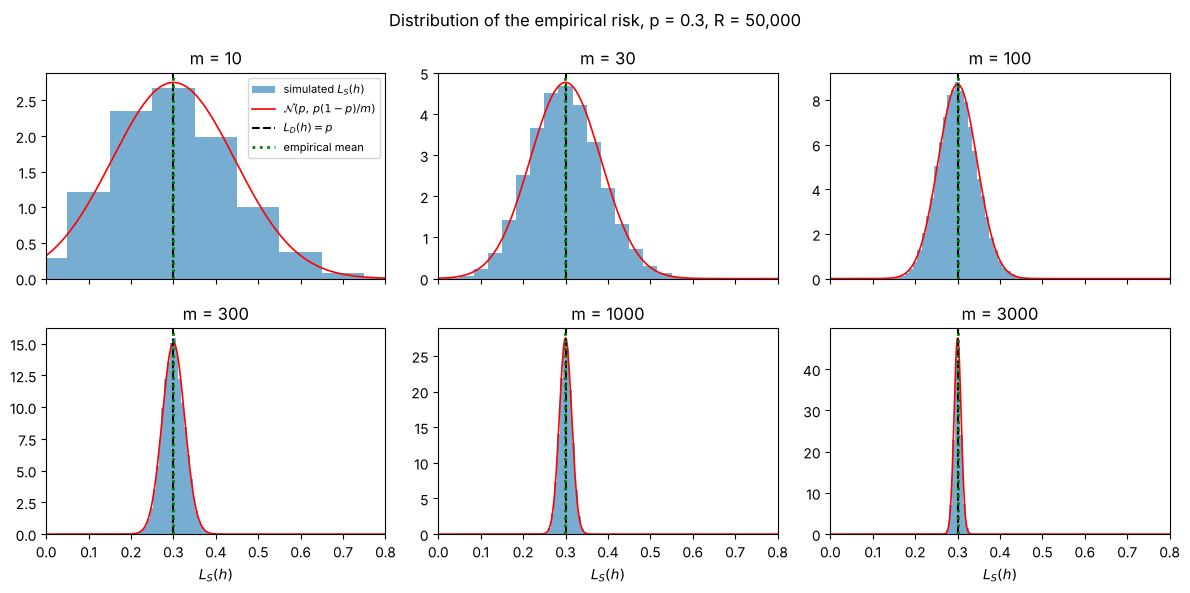

In [4]:
# (c) Distribution of L_S, with the Gaussian approximation and the empirical mean
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
xs = np.linspace(0, 0.8, 600)

for ax, m in zip(axes.ravel(), m_list):
    step = int(np.ceil(m / 150))
    bins = (np.arange(0, m + step + 1, step) - 0.5) / m
    ax.hist(LS[m], bins=bins, density=True, alpha=0.6, label="simulated $L_S(h)$")

    # Gaussian approximation N(p, p(1-p)/m)  (central limit theorem)
    sd = np.sqrt(p * (1 - p) / m)
    ax.plot(xs, np.exp(-(xs - p)**2 / (2 * sd**2)) / (sd * np.sqrt(2 * np.pi)),
            color="red", linewidth=1.2, label=r"$\mathcal{N}(p,\,p(1-p)/m)$")

    ax.axvline(p, color="black", linestyle="--", label="$L_D(h) = p$")
    ax.axvline(LS[m].mean(), color="green", linestyle=":", linewidth=2, label="empirical mean")
    ax.set_title(f"m = {m}")
    ax.set_xlim(0, 0.8)

axes[0, 0].legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("$L_S(h)$")
fig.suptitle(f"Distribution of the empirical risk, p = {p}, R = {R:,}")
plt.tight_layout()
plt.show()

**Reading the figure.**
- The empirical mean (green dotted line) and the true risk $p = 0.3$ (black dashed line) coincide
  for every $m$: $L_S(h)$ is centred on $L_\mathcal{D}(h)$.
- The histograms become narrower as $m$ increases: for $m = 10$, $L_S$ takes values roughly between
  0 and 0.7, whereas for $m = 3000$ it stays between about 0.28 and 0.32. All panels share the same
  horizontal axis, so the widths can be compared directly.
- Since the area under each histogram equals 1, a narrower distribution must be higher: the peak
  grows from about 2.7 ($m=10$) to about 47 ($m=3000$), i.e. like $\sqrt{m}$, which mirrors the
  $1/\sqrt{m}$ decrease of the standard deviation. (The vertical scales differ between panels.)
- For $m = 10$ the distribution is discrete (11 possible values) and slightly right-skewed, because
  $L_S$ cannot be negative. The Gaussian curve (red) fits poorly and even puts some mass below 0:
  the normal approximation is not reliable for very small samples.
- From $m = 30$ onwards, the histogram follows the Gaussian $\mathcal{N}(p,\,p(1-p)/m)$ closely,
  as predicted by the central limit theorem.

(d) : comparer la moyenne empirique avec p

In [5]:
# (d) Empirical mean of L_S vs true risk p
print(f"{'m':>6} {'mean L_S':>10} {'true p':>8} {'|mean - p|':>11}")
for m in m_list:
    mean = LS[m].mean()
    print(f"{m:>6} {mean:>10.4f} {p:>8.2f} {abs(mean - p):>11.5f}")

     m   mean L_S   true p  |mean - p|
    10     0.2990     0.30     0.00099
    30     0.2995     0.30     0.00048
   100     0.2998     0.30     0.00020
   300     0.3000     0.30     0.00002
  1000     0.2999     0.30     0.00011
  3000     0.3000     0.30     0.00004


 **variabilité de L_S en fonction de m**

In [6]:
print(f"{'m':>6} {'std simulated':>14} {'std theory':>11}")
for m in m_list:
    print(f"{m:>6} {LS[m].std():>14.4f} {np.sqrt(p * (1 - p) / m):>11.4f}")

     m  std simulated  std theory
    10         0.1447      0.1449
    30         0.0839      0.0837
   100         0.0458      0.0458
   300         0.0263      0.0265
  1000         0.0145      0.0145
  3000         0.0084      0.0084


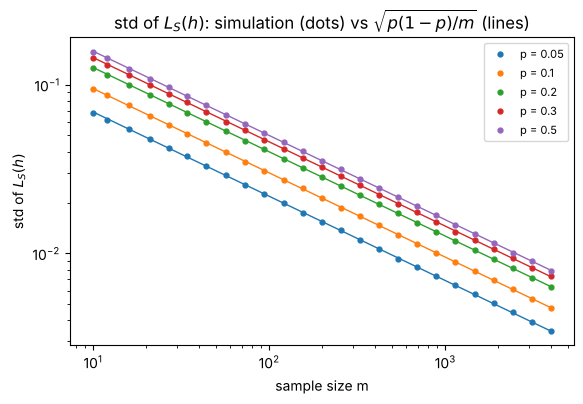

In [7]:
# Standard deviation of L_S as a function of m, for ALL chosen true risks p_1, ..., p_K
m_grid = np.unique(np.logspace(1, 3.6, 25).astype(int))   # 25 values from 10 to ~4000
R_std = 20_000

fig, ax = plt.subplots(figsize=(6.5, 4))
for pj in p_values:
    sds = [(rng.binomial(m, pj, size=R_std) / m).std() for m in m_grid]
    line, = ax.loglog(m_grid, np.sqrt(pj * (1 - pj) / m_grid), "-", linewidth=1)   # theory
    ax.loglog(m_grid, sds, "o", markersize=3.5, color=line.get_color(), label=f"p = {pj}")  # simulation

ax.set_xlabel("sample size m")
ax.set_ylabel("std of $L_S(h)$")
ax.set_title(r"std of $L_S(h)$: simulation (dots) vs $\sqrt{p(1-p)/m}$ (lines)")
ax.legend(fontsize=8)
plt.show()

**Reading the figure (log-log scale).**
- For all five values of $p$, the simulated standard deviations (dots) lie exactly on the
  theoretical curves $\sqrt{p(1-p)/m}$ (lines).
- In log-log scale every curve is a straight line, since
  $\log \mathrm{sd}(L_S) = \log\sqrt{p(1-p)} - \tfrac12 \log m$: the slope is $-1/2$.
  For example, for $p = 0.5$ the standard deviation goes from about $0.16$ at $m = 10$ to about
  $0.016$ at $m = 1000$: 100 times more data divide the spread by 10.
- The lines are parallel: the rate of concentration $1/\sqrt{m}$ is the same for every hypothesis;
  only the level, $\sqrt{p(1-p)}$, depends on $p$.
- The lines are ordered by $p(1-p)$: $p = 0.5$ (maximal variance) is the highest and $p = 0.05$ the
  lowest, with a constant ratio $\sqrt{0.25/0.0475} \approx 2.3$. The curves for $p = 0.3$ and
  $p = 0.5$ are close because $p(1-p)$ varies little near $0.5$.
- Consequence for the next questions: when several hypotheses are considered simultaneously, the
  largest deviations will come from the hypotheses with $p$ close to $0.5$.

 **Interpretation of Question 1**

### Interpretation of Question 1

**(d) Mean of $L_S(h)$ vs true risk.**
For every sample size, the empirical mean of $L_S(h)$ (green dotted line on the histograms) is
very close to the true risk $L_\mathcal{D}(h) = p = 0.3$ (black dashed line): the largest gap is
about $10^{-3}$ (at $m = 10$), which is of the same order as the Monte-Carlo error of the mean
($0.145/\sqrt{50{,}000} \approx 6.5 \times 10^{-4}$). The empirical risk is therefore an
**unbiased estimator** of the true risk, even for small samples.

**Variability of $L_S(h)$ as $m$ increases.**

| $m$ | std of $L_S$ (simulated) | $\sqrt{p(1-p)/m}$ (theory) |
|---|---|---|
| 10 | 0.1447 | 0.1449 |
| 100 | 0.0458 | 0.0458 |
| 1000 | 0.0145 | 0.0145 |
| 3000 | 0.0084 | 0.0084 |

- The simulated standard deviation matches the theoretical value $\sqrt{p(1-p)/m}$ almost exactly.
- It decreases like $1/\sqrt{m}$: multiplying $m$ by 100 (from 10 to 1000) divides the spread by 10.
- With $m = 10$, values of $L_S$ between 0.1 and 0.5 are common although the true risk is 0.3:
  a small sample can be very misleading. With $m = 3000$, $L_S$ almost always lies between
  0.28 and 0.32.

**(c) Shape of the distribution.**
For small $m$ the distribution is discrete (only $m+1$ possible values) and slightly asymmetric.
As $m$ grows, it becomes bell-shaped and matches the Gaussian approximation
$\mathcal{N}(p,\,p(1-p)/m)$ (red curve), as predicted by the central limit theorem, while
concentrating around $p$ (law of large numbers).

**Effect of the true risk $p$ (log-log figure).**
For all five values of $p$, the simulated standard deviations (dots) lie on the theoretical lines
$\sqrt{p(1-p)/m}$, which are straight lines of slope $-1/2$ in log-log scale: this confirms the
$1/\sqrt{m}$ decay for every hypothesis. Hypotheses with $p$ close to $0.5$ fluctuate the most,
since $p(1-p)$ is maximal at $0.5$; for $p = 0.05$ the standard deviation is about 2.3 times
smaller. This will matter in the uniform-convergence experiments: the largest deviations will come
from the hypotheses with the largest variance.

**Conclusion.** $L_S(h)$ is a random variable centred on $L_\mathcal{D}(h)$, whose fluctuations
shrink as $\sqrt{p(1-p)/m}$. The more data we have, the more reliable the empirical risk is as an
estimate of the true risk.

**Question 2 : écart entre risque empirique et vrai risque**

We fix the hypothesis of Question 1 ($p = 0.3$) and the accuracy $\epsilon = 0.1$. For each
sample size $m$ we simulate $R = 200{,}000$ samples, compute $|L_S(h) - L_\mathcal{D}(h)|$ for each
of them, and estimate $\Pr[|L_S(h) - L_\mathcal{D}(h)| > \epsilon]$ by the proportion of samples
whose deviation exceeds $\epsilon$. We compare it with Hoeffding's bound $2e^{-2m\epsilon^2}$.

**Choices.** $\epsilon = 0.1$: the bound is below 1 as soon as $m > \ln 2/(2\epsilon^2) \approx 35$,
so the range $m = 10$ to $1000$ covers both the regime where the bound is trivial and the regime
where it is informative. $R = 200{,}000$ allows us to detect probabilities down to
$1/R = 5 \times 10^{-6}$.

In [8]:
eps = 0.1
m_grid2 = np.unique(np.logspace(1, 3, 30).astype(int))   # 30 sample sizes from 10 to 1000
R2 = 200_000

def hoeffding(m, eps):
    """Hoeffding bound 2 exp(-2 m eps^2), clipped at 1 (a probability cannot exceed 1)."""
    return np.minimum(1.0, 2 * np.exp(-2 * np.asarray(m) * eps**2))

prob2 = []
for m in m_grid2:
    LS_ = rng.binomial(m, p, size=R2) / m          # R2 empirical risks of h
    dev = np.abs(LS_ - p)                          # |L_S(h) - L_D(h)| for every sample
    prob2.append(np.mean(dev > eps + 1e-12))       # proportion of samples with deviation > eps
prob2 = np.array(prob2)
bound2 = hoeffding(m_grid2, eps)

    m   simulated   Hoeffding  bound / sim
   10    3.00e-01    1.00e+00          3.3
   11    5.24e-01    1.00e+00          1.9
   13    3.68e-01    1.00e+00          2.7
   16    4.21e-01    1.00e+00          2.4
   18    3.05e-01    1.00e+00          3.3
   22    3.51e-01    1.00e+00          2.8
   25    1.87e-01    1.00e+00          5.3
   30    1.61e-01    1.00e+00          6.2
   35    1.38e-01    9.93e-01          7.2
   41    1.73e-01    8.81e-01          5.1
   48    1.13e-01    7.66e-01          6.8
   57    1.10e-01    6.40e-01          5.8
   67    8.17e-02    5.24e-01          6.4
   78    4.80e-02    4.20e-01          8.8
   92    4.08e-02    3.18e-01          7.8
  108    2.01e-02    2.31e-01         11.5
  126    1.52e-02    1.61e-01         10.6
  148    6.92e-03    1.04e-01         15.0
  174    3.50e-03    6.16e-02         17.6
  204    1.56e-03    3.38e-02         21.6
  239    5.85e-04    1.68e-02         28.7
  280    2.10e-04    7.40e-03         35.2
  329    7.

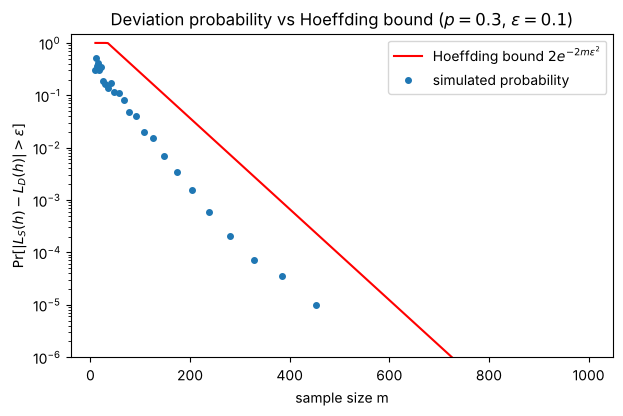

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.semilogy(m_grid2, bound2, "-", color="red", label=r"Hoeffding bound $2e^{-2m\epsilon^2}$")
pos = prob2 > 0                                    # zeros cannot be drawn on a log scale
ax.semilogy(m_grid2[pos], prob2[pos], "o", markersize=4, label="simulated probability")
ax.set_xlabel("sample size m")
ax.set_ylabel(r"$\Pr[|L_S(h) - L_D(h)| > \epsilon]$")
ax.set_title(rf"Deviation probability vs Hoeffding bound ($p = {p}$, $\epsilon = {eps}$)")
ax.set_ylim(1e-6, 1.5)
ax.legend()
plt.show()

print(f"{'m':>5} {'simulated':>11} {'Hoeffding':>11} {'bound / sim':>12}")
for m, s, b in zip(m_grid2, prob2, bound2):
    ratio = f"{b / s:12.1f}" if s > 0 else f"{'inf':>12}"
    print(f"{m:>5} {s:>11.2e} {b:>11.2e} {ratio}")

### Interpretation of Question 2

**Reading the figure.** The red line is the Hoeffding bound and the dots are the simulated
probabilities (log scale on the vertical axis, so an exponential decay appears as a straight line).
The dots disappear for $m \ge 529$: the event $|L_S - L_\mathcal{D}| > \epsilon$ happened in none of
the $200{,}000$ samples, so its probability is below about $5 \times 10^{-6}$. The small zigzags for
small $m$ come from the discreteness of $L_S = E/m$: when $m$ changes, an integer value of $E$
enters or leaves the event.

**The bound is valid.** For every $m$, the simulated probability lies below the Hoeffding bound.

**The bound is conservative, not exact.**
- For $m \le 30$ the bound equals 1 (it is $\ge 1$ before clipping) and gives no information,
  whereas the true probability is already between $0.16$ and $0.5$.
- For larger $m$ the bound overestimates the true probability by a factor that grows with $m$:
  about 8 at $m = 92$, about 22 at $m = 204$ and about 40 at $m = 329$.
- Both quantities decrease exponentially with $m$, but the true probability decreases **faster**
  (steeper slope on the log scale).

**Why.** Hoeffding's inequality only uses the fact that the loss lies in $[0, 1]$. It holds for
every distribution, so it must cover the worst case, and it ignores the actual variance
$p(1-p)$ of the losses. It is a correct guarantee with the right qualitative behaviour (exponential
decay in $m$), but not the exact value of the probability.

### Question 3 — From one hypothesis to uniform convergence

We now consider a class of $|H| = 50$ hypotheses whose true risks $p_j$ are evenly spaced between
$0.05$ and $0.5$ (from low-variance hypotheses to the worst case). For every simulated sample we
generate the 50 empirical risks $L_S(h_1), \dots, L_S(h_{50})$, compute

$$\Delta_S = \max_{h \in H} |L_S(h) - L_\mathcal{D}(h)|,$$

estimate $\Pr[\Delta_S > \epsilon]$ and compare it with the finite-class bound
$2|H|e^{-2m\epsilon^2}$. We use $\epsilon = 0.1$ and $R = 20{,}000$ samples per $m$.

In [10]:
K3 = 50
p_H = np.linspace(0.05, 0.50, K3)                  # true risks of the K hypotheses
R3 = 20_000
m_grid3 = np.unique(np.logspace(1, 3, 25).astype(int))

def uniform_bound(m, eps, K):
    """Finite-class bound 2|H| exp(-2 m eps^2), clipped at 1."""
    return np.minimum(1.0, 2 * K * np.exp(-2 * np.asarray(m) * eps**2))

prob3 = []
for m in m_grid3:
    LS_H = rng.binomial(m, p_H, size=(R3, K3)) / m     # shape (R, K): one row per sample
    Delta = np.abs(LS_H - p_H).max(axis=1)              # Delta_S for every sample
    prob3.append(np.mean(Delta > eps + 1e-12))
prob3 = np.array(prob3)
bound3 = uniform_bound(m_grid3, eps, K3)

    m   simulated       bound
   10      1.0000      1.0000
   12      1.0000      1.0000
   14      1.0000      1.0000
   17      1.0000      1.0000
   21      1.0000      1.0000
   26      1.0000      1.0000
   31      1.0000      1.0000
   38      0.9996      1.0000
   46      0.9972      1.0000
   56      0.9862      1.0000
   68      0.9489      1.0000
   82      0.8649      1.0000
  100      0.6943      1.0000
  121      0.4937      1.0000
  146      0.3008      1.0000
  177      0.1517      1.0000
  215      0.0655      1.0000
  261      0.0225      0.5407
  316      0.0073      0.1800
  383      0.0014      0.0471
  464      0.0003      0.0093
  562      0.0000      0.0013
  681      0.0001      0.0001
  825      0.0000      0.0000
 1000      0.0000      0.0000


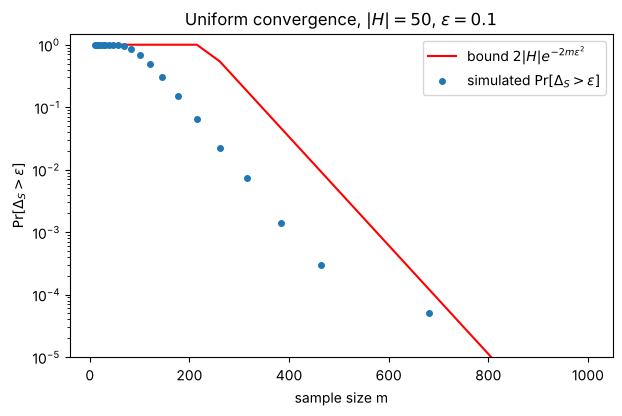

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.semilogy(m_grid3, bound3, "-", color="red", label=r"bound $2|H|e^{-2m\epsilon^2}$")
pos = prob3 > 0
ax.semilogy(m_grid3[pos], prob3[pos], "o", markersize=4, label=r"simulated $\Pr[\Delta_S > \epsilon]$")
ax.set_xlabel("sample size m")
ax.set_ylabel(r"$\Pr[\Delta_S > \epsilon]$")
ax.set_title(rf"Uniform convergence, $|H| = {K3}$, $\epsilon = {eps}$")
ax.set_ylim(1e-5, 1.5)
ax.legend()
plt.show()

print(f"{'m':>5} {'simulated':>11} {'bound':>11}")
for m, s, b in zip(m_grid3, prob3, bound3):
    print(f"{m:>5} {s:>11.4f} {b:>11.4f}")

### Interpretation of Question 3

**One hypothesis vs the whole class.** At $m \approx 100$, a single hypothesis with $p = 0.3$
deviates by more than $\epsilon$ with probability about $0.04$ (Question 2), whereas the probability
that **at least one** of the 50 hypotheses deviates is about $0.69$. Each empirical risk is
individually accurate, but with many hypotheses one of them is likely to be "unlucky".

**Why uniform convergence requires simultaneous control.** ERM chooses the hypothesis with the
smallest empirical risk *after* seeing the sample. If one hypothesis has a misleadingly small
$L_S(h)$, ERM may select precisely that one. To guarantee that the selected hypothesis is good, we
therefore need $|L_S(h) - L_\mathcal{D}(h)| \le \epsilon$ **for all** $h \in H$ at the same time,
i.e. $\Delta_S \le \epsilon$.

**Comparison with the bound.**
- The bound $2|H|e^{-2m\epsilon^2}$ is always above the simulated probability, so it is valid.
- It is very conservative: it equals 1 until $m \approx 230$, while the true probability is
  already $0.07$ at $m = 215$; at $m = 316$ the bound ($0.18$) is about 25 times the simulated
  value ($0.0073$).
- The bound is obtained from the union bound
  $\Pr[\exists h: |L_S(h) - L_\mathcal{D}(h)| > \epsilon] \le \sum_h \Pr[|L_S(h) - L_\mathcal{D}(h)| > \epsilon]$
  combined with Hoeffding for each hypothesis. It adds the looseness of Hoeffding (Question 2) to
  the looseness of replacing the probability of a union by a sum, and it treats every hypothesis as
  a worst case, although hypotheses with small $p_j$ deviate much less (Question 1).

### Question 4 — Effect of the size of the hypothesis class

We fix $\epsilon = 0.1$ and repeat the uniform-convergence experiment for
$|H| = 5, 10, 50, 100, 500$. The true risks are drawn once uniformly in $[0.05, 0.5]$ and the
classes are nested ($H_5 \subset H_{10} \subset \dots \subset H_{500}$: a larger class contains all
the hypotheses of a smaller one), so that only the number of hypotheses changes between classes.
We use $R = 5{,}000$ samples per value of $m$.

In [12]:
H_sizes = [5, 10, 50, 100, 500]
p_pool = rng.uniform(0.05, 0.50, size=max(H_sizes))    # nested classes: first K hypotheses
R4 = 5_000
m_grid4 = np.arange(10, 801, 20)

def prob_uniform(m, pK, R, eps):
    """Monte-Carlo estimate of Pr[Delta_S > eps] for a class with true risks pK."""
    LS_H = rng.binomial(m, pK, size=(R, len(pK))) / m
    return np.mean(np.abs(LS_H - pK).max(axis=1) > eps + 1e-12)

prob4 = {K: np.array([prob_uniform(m, p_pool[:K], R4, eps) for m in m_grid4]) for K in H_sizes}

    m     |H|=5    |H|=10    |H|=50   |H|=100   |H|=500
   10     0.958     0.997     1.000     1.000     1.000
   70     0.221     0.399     0.943     0.995     1.000
  130     0.038     0.090     0.424     0.687     0.996
  190     0.010     0.022     0.116     0.228     0.729
  250     0.001     0.007     0.027     0.059     0.261
  310     0.000     0.002     0.008     0.013     0.078
  370     0.000     0.000     0.003     0.005     0.020
  430     0.000     0.000     0.000     0.000     0.005
  490     0.000     0.000     0.000     0.000     0.001
  550     0.000     0.000     0.000     0.000     0.000
  610     0.000     0.000     0.000     0.000     0.000
  670     0.000     0.000     0.000     0.000     0.000
  730     0.000     0.000     0.000     0.000     0.000
  790     0.000     0.000     0.000     0.000     0.000


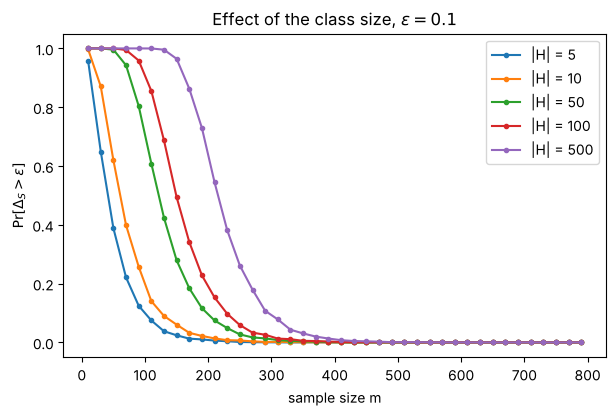

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for K in H_sizes:
    ax.plot(m_grid4, prob4[K], "o-", markersize=3, label=f"|H| = {K}")
ax.set_xlabel("sample size m")
ax.set_ylabel(r"$\Pr[\Delta_S > \epsilon]$")
ax.set_title(rf"Effect of the class size, $\epsilon = {eps}$")
ax.legend()
plt.show()

print(f"{'m':>5} " + " ".join(f"{'|H|='+str(K):>9}" for K in H_sizes))
for i in range(0, len(m_grid4), 3):
    print(f"{m_grid4[i]:>5} " + " ".join(f"{prob4[K][i]:>9.3f}" for K in H_sizes))

### Interpretation of Question 4

**How increasing $|H|$ affects uniform convergence.** At a fixed $m$, $\Pr[\Delta_S > \epsilon]$
increases with $|H|$. For example at $m = 130$ it equals $0.04$ for $|H| = 5$, $0.42$ for
$|H| = 50$ and $0.996$ for $|H| = 500$. Every additional hypothesis is one more chance that some
empirical risk is far from its true risk, so simultaneous control becomes harder.

**A larger class requires more data.** The curves move to the right when $|H|$ grows: to obtain
the same failure probability, a larger class needs a larger sample. At $m = 250$ the failure
probability is still $0.26$ for $|H| = 500$, while it is almost 0 for $|H| = 5$.

**Relation with the $\log|H|$ dependence.** The shift is small compared with the growth of $|H|$:
multiplying the number of hypotheses by 100 (from 5 to 500) moves the curves by roughly 200
samples, not by a factor 100. This agrees with the finite-class bound: solving
$2|H|e^{-2m\epsilon^2} \le \delta$ gives $m \ge \frac{\log|H| + \log(2/\delta)}{2\epsilon^2}$, in which
$|H|$ only appears through $\log|H|$. Multiplying $|H|$ by 10 adds only
$\log 10/(2\epsilon^2) \approx 115$ samples to the theoretical sample size.

### Question 5 — Experimental sample complexity

We fix $\epsilon = 0.1$ and $\delta = 0.05$. For each class of Question 4 we test
$m = 10, 15, 20, \dots, 700$ (step 5) and record the smallest tested $m$ such that the estimated
$\Pr[\Delta_S > \epsilon] \le \delta$ ($R = 10{,}000$ samples per $m$). We compare it with the
theoretical sufficient sample size

$$m \ge \frac{\log(2|H|/\delta)}{2\epsilon^2}.$$

In [14]:
delta = 0.05
R5 = 10_000
m_grid5 = np.arange(10, 701, 5)

print(f"eps = {eps}, delta = {delta}")
print(f"{'|H|':>5} {'m theory':>9} {'m experimental':>15} {'ratio':>7}")
for K in H_sizes:
    m_theory = np.log(2 * K / delta) / (2 * eps**2)
    m_exp = None
    for m in m_grid5:
        if prob_uniform(m, p_pool[:K], R5, eps) <= delta:
            m_exp = m
            break
    print(f"{K:>5} {m_theory:>9.1f} {m_exp:>15} {m_theory / m_exp:>7.2f}")

eps = 0.1, delta = 0.05
  |H|  m theory  m experimental   ratio
    5     264.9             130    2.04
   10     299.6             160    1.87
   50     380.0             235    1.62
  100     414.7             260    1.60
  500     495.2             330    1.50


### Interpretation of Question 5

- For every class, the experimental sample size is clearly **smaller** than the theoretical one:
  about 2 times smaller for $|H| = 5$ ($130$ vs $265$) and 1.5 times smaller for $|H| = 500$
  ($330$ vs $495$).
- Both increase slowly with $|H|$: from $|H| = 5$ to $|H| = 500$, the experimental value increases
  by $200$ samples and the theoretical value by $230$ samples, which confirms the logarithmic
  dependence on $|H|$.

**Why the theoretical bound is a sufficient guarantee and not the exact minimum.** The formula
$m \ge \log(2|H|/\delta)/(2\epsilon^2)$ is derived from two worst-case inequalities:
1. Hoeffding's inequality, which holds for every distribution of the losses on $[0, 1]$ and
   ignores their actual variance;
2. the union bound, which holds for any dependence between the hypotheses and replaces the
   probability that at least one hypothesis deviates by the sum of the individual probabilities.

Any $m$ satisfying the formula **guarantees** $\Pr[\Delta_S > \epsilon] \le \delta$, whatever the
true risks of the hypotheses. For a particular class, as here, the guarantee is reached with fewer
samples. The bound answers "how many samples are always enough?", not "how many samples are
needed for this specific problem?".

---
## Part II — Simulating No-Free-Lunch

The domain is $\mathcal{X} = \{1, \dots, N\}$ with the uniform distribution. In each repetition a new
target function is generated with $f(x) \sim \mathrm{Bernoulli}(1/2)$ independently for every $x$,
and a training sample $S \sim \mathcal{D}^m$ is drawn. The learner predicts the observed label on
inputs that appear in $S$ and predicts $0$ on the others. (In the code the inputs are stored as
indices $0, \dots, N-1$.)

### Question 6 — Seen and unseen inputs

**Choices.** $N = 20, 100, 1000$ and $m/N$ from $0$ to $4$, to check that the result depends on
the ratio $m/N$; $R = 2{,}000$ repetitions.

In [15]:
def draw_sample(N, m, R):
    """R training samples of size m from the uniform distribution on X.
    Returns the inputs X (shape (R, m)) and a mask seen[r, x] = True if x appears in sample r."""
    X = rng.integers(0, N, size=(R, m))
    seen = np.zeros((R, N), dtype=bool)
    seen[np.arange(R)[:, None], X] = True
    return X, seen

def random_target(N, R):
    """R random target functions: f(x) ~ Bernoulli(1/2) independently for every x."""
    return (rng.random((R, N)) < 0.5).astype(int)

N_list = [20, 100, 1000]
ratios = np.array([0, 0.1, 0.25, 0.5, 0.75, 1, 1.5, 2, 2.5, 3, 4])   # values of m / N
R6 = 2_000

unseen6 = {}
for N in N_list:
    ms = (ratios * N).astype(int)
    frac = []
    for m in ms:
        f = random_target(N, R6)                   # (a) random target
        X, seen = draw_sample(N, m, R6)            # (b) training sample
        frac.append((~seen).mean())                # (c) fraction of unseen inputs, averaged over R
    unseen6[N] = (ms, np.array(frac))

    N     m  simulated  (1-1/N)^m
   20     0     1.0000     1.0000
   20     2     0.9024     0.9025
   20     5     0.7739     0.7738
   20    10     0.5986     0.5987
   20    15     0.4652     0.4633
   20    20     0.3562     0.3585
   20    30     0.2140     0.2146
   20    40     0.1263     0.1285
   20    50     0.0779     0.0769
   20    60     0.0446     0.0461
   20    80     0.0171     0.0165
  100     0     1.0000     1.0000
  100    10     0.9043     0.9044
  100    25     0.7783     0.7778
  100    50     0.6050     0.6050
  100    75     0.4699     0.4706
  100   100     0.3663     0.3660
  100   150     0.2218     0.2215
  100   200     0.1342     0.1340
  100   250     0.0820     0.0811
  100   300     0.0492     0.0490
  100   400     0.0181     0.0180
 1000     0     1.0000     1.0000
 1000   100     0.9048     0.9048
 1000   250     0.7786     0.7787
 1000   500     0.6063     0.6064
 1000   750     0.4722     0.4722
 1000  1000     0.3681     0.3677
 1000  1500   

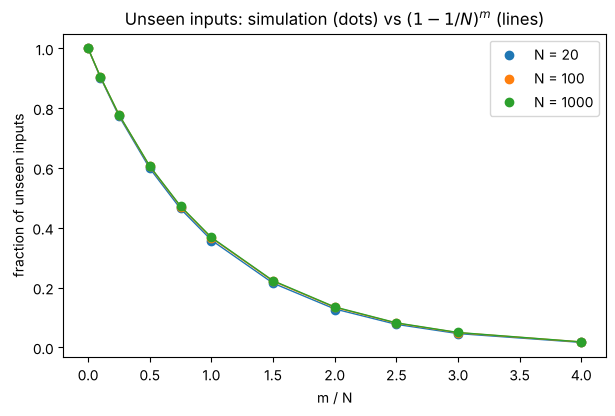

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for N in N_list:
    ms, frac = unseen6[N]
    line, = ax.plot(ms / N, (1 - 1 / N) ** ms, "-", linewidth=1)
    ax.plot(ms / N, frac, "o", color=line.get_color(), label=f"N = {N}")
ax.set_xlabel("m / N")
ax.set_ylabel("fraction of unseen inputs")
ax.set_title(r"Unseen inputs: simulation (dots) vs $(1 - 1/N)^m$ (lines)")
ax.legend()
plt.show()

print(f"{'N':>5} {'m':>5} {'simulated':>10} {'(1-1/N)^m':>10}")
for N in N_list:
    ms, frac = unseen6[N]
    for m, s in zip(ms, frac):
        print(f"{N:>5} {m:>5} {s:>10.4f} {(1 - 1 / N) ** m:>10.4f}")

### Interpretation of Question 6

The simulated fraction of unseen inputs agrees with $(1 - 1/N)^m$ to two or three decimals for
all values of $N$ and $m$ (for example $0.366$ for $N = 100$, $m = 100$). The three curves are
almost identical when plotted against $m/N$, because $(1 - 1/N)^m \approx e^{-m/N}$.

**Why it is also the expected fraction.** A fixed input $x$ is missed by one draw with probability
$1 - 1/N$, and the $m$ draws are independent, so $\Pr[x \text{ unseen}] = (1 - 1/N)^m$. The
fraction of unseen inputs is $U = \frac1N \sum_{x} \mathbf{1}[x \text{ unseen}]$, and by linearity
of expectation

$$\mathbb{E}[U] = \frac1N \sum_{x \in \mathcal{X}} \Pr[x \text{ unseen}] = \left(1 - \frac1N\right)^m.$$

Even with $m = N$ samples, about $37\%$ of the domain has never been observed ($e^{-1} \approx 0.37$),
and with $m = 2N$ about $13.5\%$ is still unseen.

### Question 7 — Error on unseen inputs

The true risk of the memorization learner over the whole domain is

$$L_\mathcal{D}(A(S)) = \frac{1}{N}\sum_{x \in \mathcal{X}} \mathbf{1}[A(S)(x) \ne f(x)].$$

**Derivation of the expected risk.** On a seen input the learner returns the observed label, which
is $f(x)$, so it makes no error. On an unseen input it predicts $0$ and is wrong iff $f(x) = 1$.
Hence $L_\mathcal{D}(A(S)) = \frac1N \sum_x \mathbf{1}[x \text{ unseen}]\,\mathbf{1}[f(x) = 1]$.
The sample inputs are independent of the labels, and $\Pr[f(x) = 1] = 1/2$, so

$$\mathbb{E}[L_\mathcal{D}(A(S))] = \frac1N \sum_x \Pr[x \text{ unseen}] \cdot \frac12
= \frac12\left(1 - \frac1N\right)^m.$$

We take $N = 100$ and $R = 3{,}000$ repetitions (new target and new sample each time).

In [17]:
def memorization_risk(f, seen, rule="zero"):
    """True risk of the learner that copies observed labels and uses `rule` on unseen inputs."""
    if rule == "zero":
        guess = np.zeros_like(f)
    elif rule == "one":
        guess = np.ones_like(f)
    elif rule == "random":
        guess = (rng.random(f.shape) < 0.5).astype(int)
    pred = np.where(seen, f, guess)                # observed label if seen, rule otherwise
    return (pred != f).mean(axis=1)                # L_D(A(S)) for each repetition

N7 = 100
R7 = 3_000
m_grid7 = np.array([0, 5, 10, 20, 30, 50, 75, 100, 150, 200, 250, 300, 400])

risk7 = []
for m in m_grid7:
    f = random_target(N7, R7)
    X, seen = draw_sample(N7, m, R7)
    risk7.append(memorization_risk(f, seen, "zero").mean())
risk7 = np.array(risk7)
theory7 = 0.5 * (1 - 1 / N7) ** m_grid7

    m  simulated   theory
    0     0.4990   0.5000
    5     0.4759   0.4755
   10     0.4521   0.4522
   20     0.4081   0.4090
   30     0.3712   0.3699
   50     0.3027   0.3025
   75     0.2356   0.2353
  100     0.1837   0.1830
  150     0.1098   0.1107
  200     0.0666   0.0670
  250     0.0404   0.0405
  300     0.0246   0.0245
  400     0.0091   0.0090


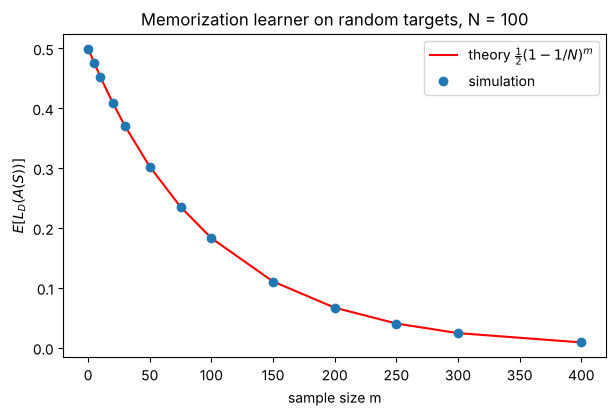

In [18]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(m_grid7, theory7, "-", color="red", label=r"theory $\frac{1}{2}(1 - 1/N)^m$")
ax.plot(m_grid7, risk7, "o", label="simulation")
ax.set_xlabel("sample size m")
ax.set_ylabel(r"$E[L_D(A(S))]$")
ax.set_title(f"Memorization learner on random targets, N = {N7}")
ax.legend()
plt.show()

print(f"{'m':>5} {'simulated':>10} {'theory':>8}")
for m, s, t in zip(m_grid7, risk7, theory7):
    print(f"{m:>5} {s:>10.4f} {t:>8.4f}")

### Interpretation of Question 7

- The simulated expected risk agrees with $\frac12(1 - 1/N)^m$ for every $m$ (differences of the
  order of $10^{-3}$, i.e. Monte-Carlo error).
- The training error of this learner is always $0$, since it copies the observed labels, but its
  true risk is close to $0.5$ when $m$ is small: it fits the sample perfectly and learns nothing
  about the rest of the domain.
- The risk is exactly half of the fraction of unseen inputs (Question 6): the learner is always
  right on seen inputs and wrong on half of the unseen ones. The risk decreases with $m$ only
  because more inputs are observed, not because the learner generalizes.

### Question 8 — Changing the prediction on unseen inputs

Same setting as Question 7 ($N = 100$, random targets), with three rules on unseen inputs:
always predict 0, always predict 1, predict a random Bernoulli(1/2) label.

    m     zero      one   random   theory
    0   0.4990   0.5010   0.4989   0.5000
    5   0.4754   0.4756   0.4753   0.4755
   10   0.4520   0.4523   0.4515   0.4522
   20   0.4085   0.4094   0.4088   0.4090
   30   0.3695   0.3701   0.3711   0.3699
   50   0.3025   0.3024   0.3010   0.3025
   75   0.2357   0.2348   0.2346   0.2353
  100   0.1832   0.1836   0.1838   0.1830
  150   0.1106   0.1110   0.1112   0.1107
  200   0.0668   0.0680   0.0672   0.0670
  250   0.0404   0.0402   0.0404   0.0405
  300   0.0248   0.0246   0.0249   0.0245
  400   0.0086   0.0089   0.0087   0.0090


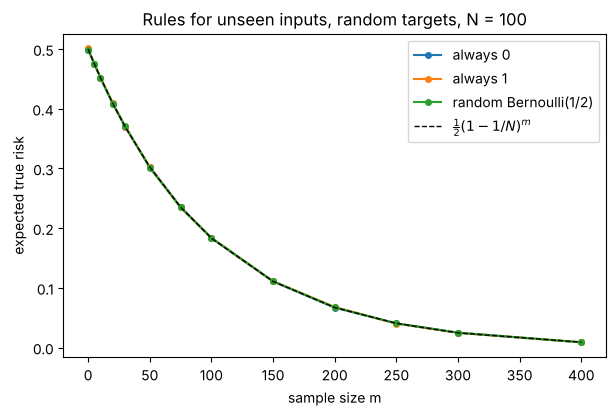

In [19]:
rules = {"zero": "always 0", "one": "always 1", "random": "random Bernoulli(1/2)"}
risk8 = {r: [] for r in rules}
for m in m_grid7:
    f = random_target(N7, R7)
    X, seen = draw_sample(N7, m, R7)
    for r in rules:
        risk8[r].append(memorization_risk(f, seen, r).mean())

fig, ax = plt.subplots(figsize=(7, 4.2))
for r, label in rules.items():
    ax.plot(m_grid7, risk8[r], "o-", markersize=4, label=label)
ax.plot(m_grid7, theory7, "k--", linewidth=1, label=r"$\frac{1}{2}(1 - 1/N)^m$")
ax.set_xlabel("sample size m")
ax.set_ylabel("expected true risk")
ax.set_title(f"Rules for unseen inputs, random targets, N = {N7}")
ax.legend()
plt.show()

print(f"{'m':>5} " + " ".join(f"{r:>8}" for r in rules) + f" {'theory':>8}")
for i, m in enumerate(m_grid7):
    print(f"{m:>5} " + " ".join(f"{risk8[r][i]:>8.4f}" for r in rules) + f" {theory7[i]:>8.4f}")

### Interpretation of Question 8

**No strategy outperforms the others.** The three curves coincide with $\frac12(1 - 1/N)^m$ for
every $m$; the differences between rules are of the order of $10^{-3}$, i.e. Monte-Carlo error.

**Why.** For an unseen input $x$, the label $f(x)$ is a fair coin that is independent of the
training sample. Whatever the rule predicts on $x$ (0, 1 or a random label), it is wrong with
probability exactly $1/2$. The training sample contains no information about the unseen labels.

**Relation with the No-Free-Lunch principle.** When targets are drawn uniformly among all possible
labelings, every learning algorithm has the same expected error on the inputs it has not seen.
A rule can only be better on some targets (for example "always 0" is perfect when $f \equiv 0$) by
being worse on others (it is bad when $f \equiv 1$), and these gains and losses cancel on average.
Without assumptions on the target, a learner cannot infer the labels of unseen inputs from the
training sample alone.

---
## Part III — Introducing Prior Knowledge

The target is now a threshold function $f_\theta(x) = \mathbf{1}[x > \theta]$ with $\theta$ drawn
uniformly in $\{1, \dots, N-1\}$, and the learner uses the threshold class
$H = \{h_t(x) = \mathbf{1}[x > t] : t \in \{1, \dots, N-1\}\}$.

### Question 9 — Learning with a matching inductive bias

**ERM.** For each threshold $t$, the empirical error is the number of training examples with label
1 and $x \le t$ plus the number with label 0 and $x > t$. We compute it for all $N - 1$ thresholds
(with cumulative counts) and select a threshold with minimal empirical error (the smallest one in
case of ties). Same $N = 100$, sample sizes and number of repetitions as in Part II, so the results
can be compared directly.

In [20]:
def threshold_target(N, R):
    """R threshold targets f_theta(x) = 1[x > theta], theta uniform in {1, ..., N-1}."""
    theta = rng.integers(1, N, size=R)
    x = np.arange(1, N + 1)
    return (x[None, :] > theta[:, None]).astype(int)

def erm_threshold(f, X):
    """ERM over the thresholds t = 1..N-1. Returns the selected threshold for each repetition."""
    R, N = f.shape
    y = np.take_along_axis(f, X, axis=1)                     # labels of the training inputs
    rows = np.repeat(np.arange(R), X.shape[1])
    count1 = np.zeros((R, N)); count0 = np.zeros((R, N))
    np.add.at(count1, (rows, X.ravel()), y.ravel())          # number of label-1 examples at each x
    np.add.at(count0, (rows, X.ravel()), 1 - y.ravel())      # number of label-0 examples at each x
    cum1, cum0 = np.cumsum(count1, axis=1), np.cumsum(count0, axis=1)
    # threshold t = j + 1 predicts 0 on inputs 1..t (indices 0..j) and 1 on the others
    emp_err = cum1[:, :-1] + (count0.sum(axis=1, keepdims=True) - cum0[:, :-1])
    return emp_err.argmin(axis=1) + 1                        # smallest minimiser

def threshold_risk(t, f):
    """True risk over the whole domain of h_t(x) = 1[x > t]."""
    x = np.arange(1, f.shape[1] + 1)
    pred = (x[None, :] > t[:, None]).astype(int)
    return (pred != f).mean(axis=1)

risk9 = []
for m in m_grid7:
    f = threshold_target(N7, R7)                   # (a) threshold target
    X, seen = draw_sample(N7, m, R7)               # (b) training sample
    t_hat = erm_threshold(f, X)                    # (c) ERM
    risk9.append(threshold_risk(t_hat, f).mean())  # (d) true risk over the whole domain
risk9 = np.array(risk9)

print(f"N = {N7}, R = {R7:,}")
print(f"{'m':>5} {'threshold ERM':>14} {'random targets (Q7)':>20}")
for m, a, b in zip(m_grid7, risk9, risk7):
    print(f"{m:>5} {a:>14.4f} {b:>20.4f}")

N = 100, R = 3,000
    m  threshold ERM  random targets (Q7)
    0         0.4934               0.4990
    5         0.1380               0.4759
   10         0.0774               0.4521
   20         0.0409               0.4081
   30         0.0272               0.3712
   50         0.0146               0.3027
   75         0.0086               0.2356
  100         0.0056               0.1837
  150         0.0028               0.1098
  200         0.0015               0.0666
  250         0.0009               0.0404
  300         0.0005               0.0246
  400         0.0002               0.0091


### Interpretation of Question 9

- With the same domain, the same sample sizes and the same uniform distribution, the threshold
  learner has a much smaller true risk than the memorization learner on random targets: for
  $m = 20$, $0.041$ vs $0.408$ (10 times smaller); for $m = 50$, $0.015$ vs $0.303$ (20 times
  smaller); for $m = 100$, $0.006$ vs $0.184$ (30 times smaller).
- The risk of threshold ERM decreases roughly like $1/m$ ($m \cdot \mathbb{E}[L_\mathcal{D}(h_S)]$
  stays around $0.7$–$0.8$ for $m \le 100$), whereas on random targets the risk only decreases as
  fast as the domain is covered by the sample.
- For $m = 0$ both risks are close to $0.5$: without data, no learner can do better than a guess.

### Question 10 — Random targets vs structured targets

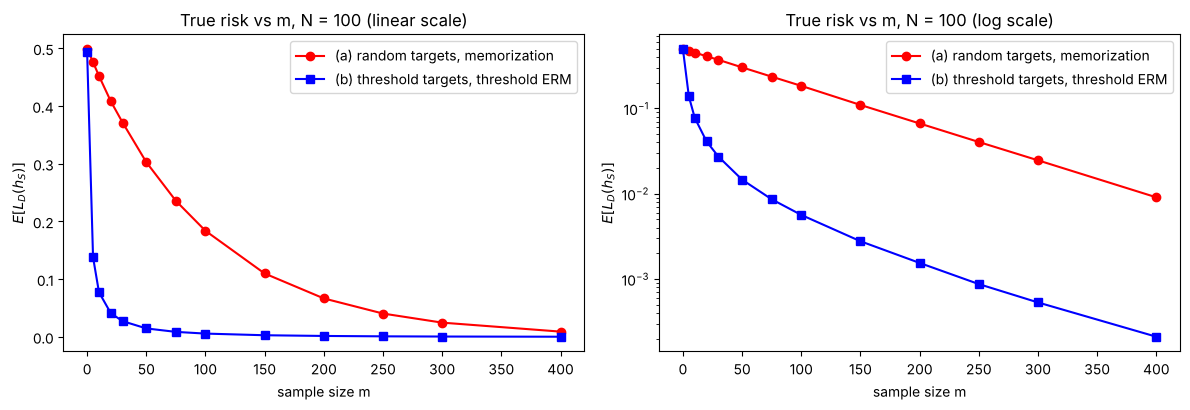

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, scale in zip(axes, ["linear", "log"]):
    ax.plot(m_grid7, risk7, "o-", color="red", label="(a) random targets, memorization")
    ax.plot(m_grid7, risk9, "s-", color="blue", label="(b) threshold targets, threshold ERM")
    ax.set_yscale(scale)
    ax.set_xlabel("sample size m")
    ax.set_ylabel(r"$E[L_D(h_S)]$")
    ax.set_title(f"True risk vs m, N = {N7} ({scale} scale)")
    ax.legend()
plt.tight_layout()
plt.show()

### Interpretation of Question 10

**Reading the figure.** Both panels show the same results (linear scale on the left, log scale on
the right). For random targets, the risk decreases slowly and stays above $0.1$ until
$m \approx 150$. For threshold targets, it falls below $0.05$ with only $20$ examples and stays one
to two orders of magnitude below the random-target curve.

**Why the learner generalizes in the second setting.** For random targets, the label of an unseen
input is independent of the training sample, so nothing can be inferred about it. For threshold
targets, the labels are linked: a training example $(x_0, 0)$ implies that $f(x) = 0$ for all
$x \le x_0$, and an example $(x_0, 1)$ implies that $f(x) = 1$ for all $x \ge x_0$. A few examples
therefore determine the labels of almost all the domain, including inputs that were never observed.
Only the inputs between the largest negative example and the smallest positive example remain
uncertain, and this interval shrinks as $m$ grows.

**Role of the assumption.** The assumption that the target belongs to the threshold family is
prior knowledge. It reduces the possible targets from $2^N$ arbitrary labelings to only $N - 1$
thresholds, and the learner searches only among these thresholds. This inductive bias is what
allows the learner to go beyond the observed examples. It works because the assumption is correct:
the generalization comes from the match between the hypothesis class and the structure of the
target, not from the data alone.

---
## 11. Final Analysis

**Concentration of $L_S(h)$ around $L_\mathcal{D}(h)$.** For a fixed hypothesis, $L_S(h)$ is an
average of $m$ independent losses. It is unbiased and its standard deviation is
$\sqrt{p(1-p)/m}$, so it becomes more concentrated around $L_\mathcal{D}(h)$ as $m$ increases
(Question 1), and the probability of a deviation larger than $\epsilon$ decreases exponentially in
$m$ (Question 2).

**Simultaneous control over all hypotheses.** ERM selects a hypothesis using the same sample on
which the risks are estimated. A guarantee for one fixed hypothesis is therefore not enough: all
empirical risks must be close to the true risks at the same time. Even when each hypothesis is
individually well estimated, the probability that at least one of them deviates can be large
($0.69$ vs $0.04$ for a single hypothesis at $m \approx 100$, Question 3).

**Effect of $|H|$.** A larger class gives more opportunities for a misleading empirical risk, so
uniform convergence needs more data (Question 4). The cost grows only like $\log|H|$: from
$|H| = 5$ to $|H| = 500$ the required sample size increases by about 200 samples (Question 5).

**Conservativeness of the finite-class bounds.** The bounds combine Hoeffding's inequality, valid
for every distribution, and the union bound, valid for any dependence between hypotheses. They are
always valid but overestimate the true probabilities (by factors from about 8 to 40 in Questions 2
and 3), and the theoretical sample size is 1.5 to 2 times the experimental one (Question 5). They
are sufficient guarantees, not exact values.

**Random targets make unseen labels unpredictable.** When every label is an independent fair coin,
the training sample says nothing about the labels of unseen inputs. A fraction $(1 - 1/N)^m$ of the
domain is never observed (Question 6), and the memorization learner, despite zero training error,
has expected risk $\frac12(1 - 1/N)^m$ (Question 7).

**No-Free-Lunch.** Predicting 0, 1 or a random label on unseen inputs gives exactly the same
expected risk (Question 8). No rule can do better than chance on unseen inputs when all targets are
equally likely: a learner cannot infer arbitrary unseen labels from the training sample alone.

**Prior knowledge through thresholds.** Assuming that the target is a threshold and restricting the
hypothesis class to thresholds introduces prior knowledge about the structure of the target. Each
observed label then determines the labels of a whole part of the domain.

**Why this inductive bias allows generalization.** With the threshold class, the true risk is 10
to 30 times smaller than with random targets for the same sample sizes, and it decreases like
$1/m$ (Questions 9 and 10). The learner predicts correctly inputs it has never seen because the
hypothesis class matches the structure of the target. Generalization beyond the observed examples
is possible only when the data are combined with a correct assumption about the target.